# EpiAI 一站式教程
从原始数据到部署预测 + 可视化

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from pathlib import Path

from EpiAI import ForecastTask
from EpiAI.dataset import TimeSplit
from EpiAI.viz import plot_test_predictions, plot_forecast

## 1. 加载数据

In [2]:
DATA_PATH = Path.home() / "infective_disease" / "pingtai" / "merged_clean.csv"
DISEASE = "登革热 Dengue fever"

df_raw = pd.read_csv(DATA_PATH)
df_raw["Year/Month"] = pd.to_datetime(df_raw["Year/Month"])
df = (
    df_raw.query("Diseases == @DISEASE")
    [["Year/Month", "Case number"]]
    .rename(columns={"Year/Month": "time", "Case number": "cases"})
    .reset_index(drop=True)
)
df = df[df["time"].dt.year >= 2010].reset_index(drop=True)
print(f"数据: {len(df)} 行, {df['time'].min().date()} → {df['time'].max().date()}")

数据: 196 行, 2010-01-01 → 2026-04-01


## 2. 定义预测任务

In [3]:
task = ForecastTask(
    data=df,
    target="cases",
    time_col="time",
    freq="MS",
    horizon=12,
    split=TimeSplit(train_end="2024-05-01", val_end="2025-05-01"),
)
print(f"Task: {task}")
print(f"季节周期: {task.freq_to_season_length()} 期/年")

Task: ForecastTask(target=['cases'], freq=MS, horizon=12)
季节周期: 12 期/年


## 3. 批量训练 + 排行榜

In [6]:
from EpiAI.models.registry import get, list_models
model_names = ['arima',
 'autoformer',
 'bsts',
 'cnn',
 'cnn-lstm',
 'dlinear',
 'ets',
#  'lgbm',
 'linearreg',
 'lstm',
 'mlp',
 'prophet',
 'resnet',
 'rf',
 'serfling',
 'sf_adida',
 'sf_arch',
 'sf_arima',
 'sf_auto_arima',
 'sf_auto_ces',
 'sf_auto_ets',
 'sf_auto_regressive',
 'sf_auto_tbats',
 'sf_auto_theta',
 'sf_croston_classic',
 'sf_croston_optimized',
 'sf_croston_sba',
 'sf_garch',
 'sf_historic_average',
 'sf_holt',
 'sf_holt_winters',
 'sf_imapa',
 'sf_mstl',
 'sf_naive',
 'sf_random_walk_drift',
 'sf_seasonal_exp_smoothing',
 'sf_seasonal_exp_smoothing_optimized',
 'sf_seasonal_naive',
 'sf_seasonal_window_average',
 'sf_simple_exp_smoothing',
 'sf_simple_exp_smoothing_optimized',
 'sf_tbats',
 'sf_theta',
 'sf_theta_dynamic',
 'sf_theta_dynamic_optimized',
 'sf_theta_optimized',
 'sf_tsb',
 'sf_window_average',
 'stlm',
 'svr',
 'tcn',
 'timesnet',
 'transformer',
 'xgb']

In [7]:
vault = task.compare(model_names, cache_dir="./test")
print("\n排行榜（按 R² 排序）:")
display(vault.summary())

  arima                           MAE=587  R²=0.589  PearsonR=0.841
         → 已缓存至 test/arima.pkl
  autoformer                      MAE=813  R²=-0.517  PearsonR=0.651
         → 已缓存至 test/autoformer.pkl
  bsts                            MAE=1266  R²=-4.368  PearsonR=0.916
         → 已缓存至 test/bsts.pkl
  cnn                             MAE=336  R²=0.814  PearsonR=0.910
         → 已缓存至 test/cnn.pkl
  cnn-lstm                        MAE=836  R²=-0.565  PearsonR=-0.048
         → 已缓存至 test/cnn-lstm.pkl
  dlinear                         MAE=601  R²=0.039  PearsonR=0.535
         → 已缓存至 test/dlinear.pkl
  ets                             MAE=478  R²=0.782  PearsonR=0.970
         → 已缓存至 test/ets.pkl
  linearreg                       MAE=495  R²=0.628  PearsonR=0.862
         → 已缓存至 test/linearreg.pkl
  lstm                            MAE=822  R²=-0.546  PearsonR=0.668
         → 已缓存至 test/lstm.pkl
  mlp                             MAE=643  R²=0.064  PearsonR=0.848
         → 已缓存至 test/mlp.pk

,paradigm,MAE,RMSE,MAPE,R2,PearsonR,n
model,,,,,,,
sf_auto_ces,ts,271.478027,486.684814,31.448820,0.808236,0.981065,12
sf_seasonal_exp_smoothing,ts,229.779984,313.855774,51.863110,0.920250,0.980784,12
sf_mstl,ts,710.879456,762.103149,328.870177,0.529783,0.974462,12
sf_auto_ets,ts,583.824707,626.709900,334.494662,0.682017,0.970803,12
sf_seasonal_window_average,ts,252.229187,410.308289,47.249067,0.863701,0.970583,12
ets,ts,477.592194,519.234924,298.268795,0.781728,0.970391,12
sf_holt_winters,ts,336.334015,391.961792,202.819920,0.875618,0.970364,12
sf_theta_dynamic_optimized,ts,796.050598,840.984070,470.833540,0.427406,0.970026,12
sf_theta,ts,833.764465,877.970154,492.347097,0.375934,0.969142,12


## 4. 测试集预测对比图

真实值（黑线） vs 各模型在测试集上的预测值（散点+虚线），图例附带 Pearson r。

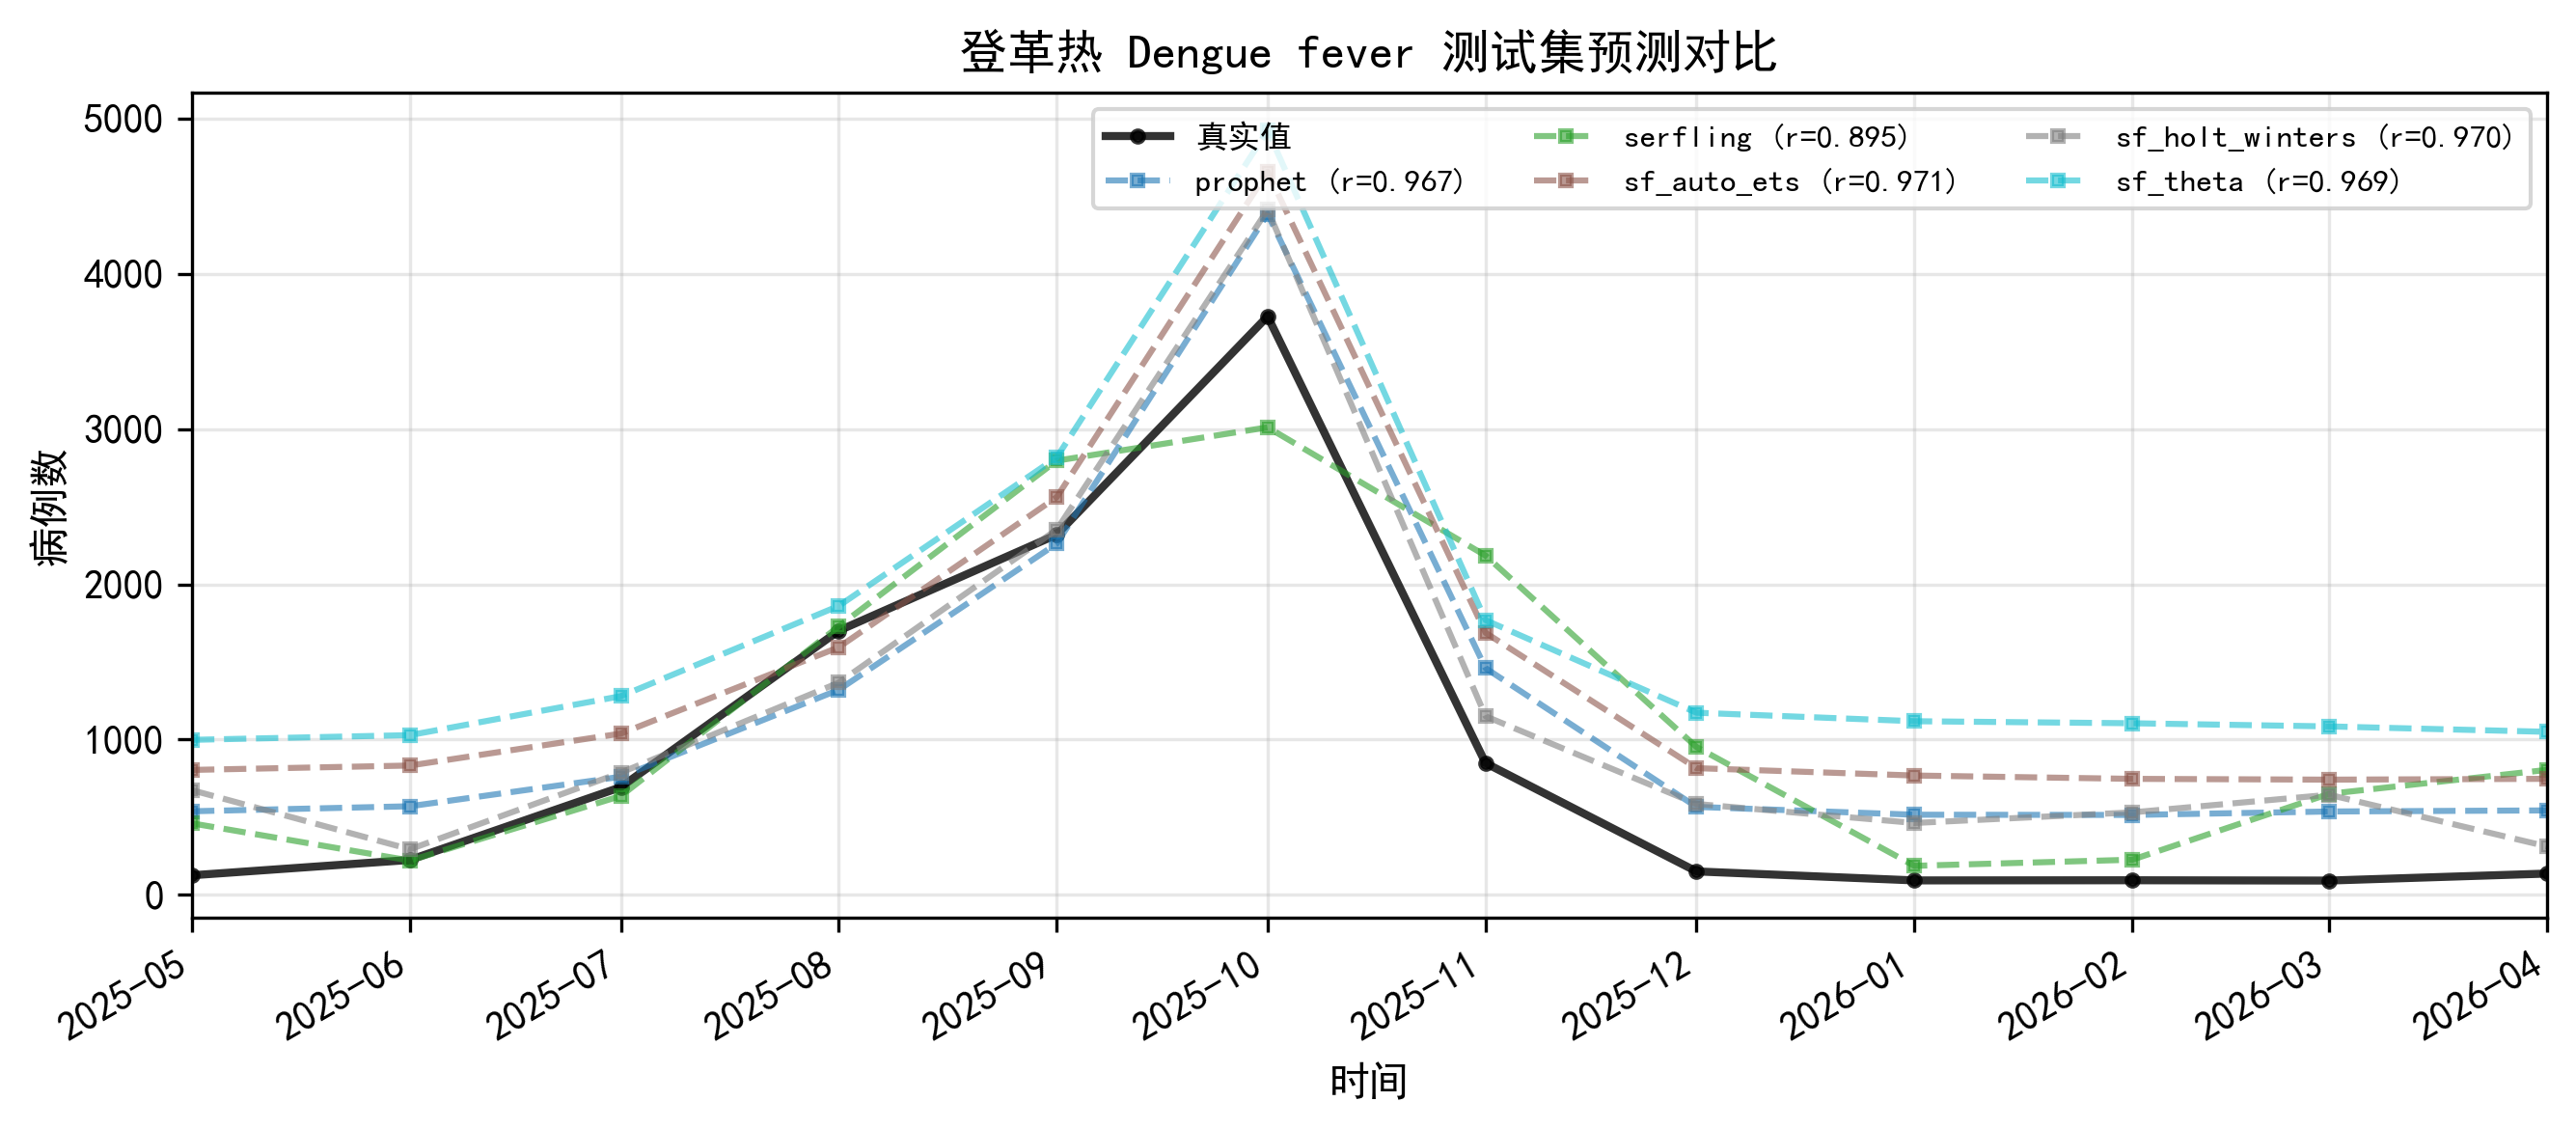

In [7]:
plot_test_predictions(
    bundle=task.build_bundle(),
    vault=vault,
    title=f"{DISEASE} 测试集预测对比",
)

## 5. 部署 + 风险评分

In [13]:
best_model = vault.best("R2")
print(f"最佳模型: {best_model}")

runtime = task.deploy(best_model, vault, risk=["quantile", "zscore"])
print(f"Runtime: {runtime}")
print(f"风险算法: {list(runtime.risk_scorers.keys())}")

最佳模型: sf_holt_winters
Runtime: DeploymentRuntime(5 models, 196 rows)
风险算法: ['quantile', 'zscore']


In [14]:
pred

,time,sf_auto_ets,sf_holt_winters,sf_theta,prophet,serfling,sf_auto_ets_lo,sf_auto_ets_hi,sf_holt_winters_lo,sf_holt_winters_hi,...,sf_holt_winters_quantile,prophet_quantile,serfling_quantile,sf_theta_quantile,sf_auto_ets_quantile,sf_holt_winters_zscore,prophet_zscore,serfling_zscore,sf_theta_zscore,sf_auto_ets_zscore
0,2026-05-01,400.919067,399.481964,403.262360,582.113647,436.531250,-4111.187012,4913.024902,-4117.645508,4916.609863,...,3,3,3,3,3,3,3,3,3,3
1,2026-06-01,475.340332,386.384979,450.948242,611.442627,210.060837,-4039.554688,4990.235352,-4130.747559,4903.517578,...,3,3,2,3,3,1,2,0,1,2
2,2026-07-01,670.437805,774.927551,716.158081,810.827942,642.785950,-3847.244629,5188.120117,-3742.210693,5292.065918,...,1,1,1,1,1,0,1,0,0,0
3,2026-08-01,1277.457886,1382.616943,1323.828613,1387.303711,1741.120850,-3243.010010,5797.925781,-3134.527588,5899.761230,...,1,1,1,1,1,0,0,0,0,0
4,2026-09-01,2230.088135,2247.890137,2259.064453,2349.130371,2796.154053,-2293.163818,6753.339844,-2269.261719,6765.041504,...,1,1,1,1,1,0,0,0,0,0
5,2026-10-01,4311.177734,4355.544922,4322.005859,4453.884277,2989.345215,-214.856155,8837.211914,-161.614502,8872.705078,...,1,1,1,1,1,0,0,0,0,0
6,2026-11-01,1342.709351,1491.722656,1394.633179,1482.129150,2148.828125,-3186.105225,5871.523926,-3025.445801,6008.891113,...,1,1,1,1,1,0,0,0,0,0
7,2026-12-01,466.575378,497.415894,520.221802,620.972046,916.694275,-4065.018066,4998.168945,-4019.762207,5014.594238,...,3,3,3,3,3,3,3,3,3,3
8,2027-01-01,420.424744,448.278809,442.040985,587.655701,161.200027,-4113.945801,4954.795410,-4068.910156,4965.467773,...,3,3,3,3,3,3,3,3,3,3
9,2027-02-01,408.808258,347.756897,429.704651,593.231323,207.142044,-4128.337891,4945.954102,-4169.443848,4864.957520,...,3,3,3,3,3,3,3,3,3,3


## 6. 未来预测图

历史曲线（最近 20 期） + 多模型未来预测 + 风险等级。

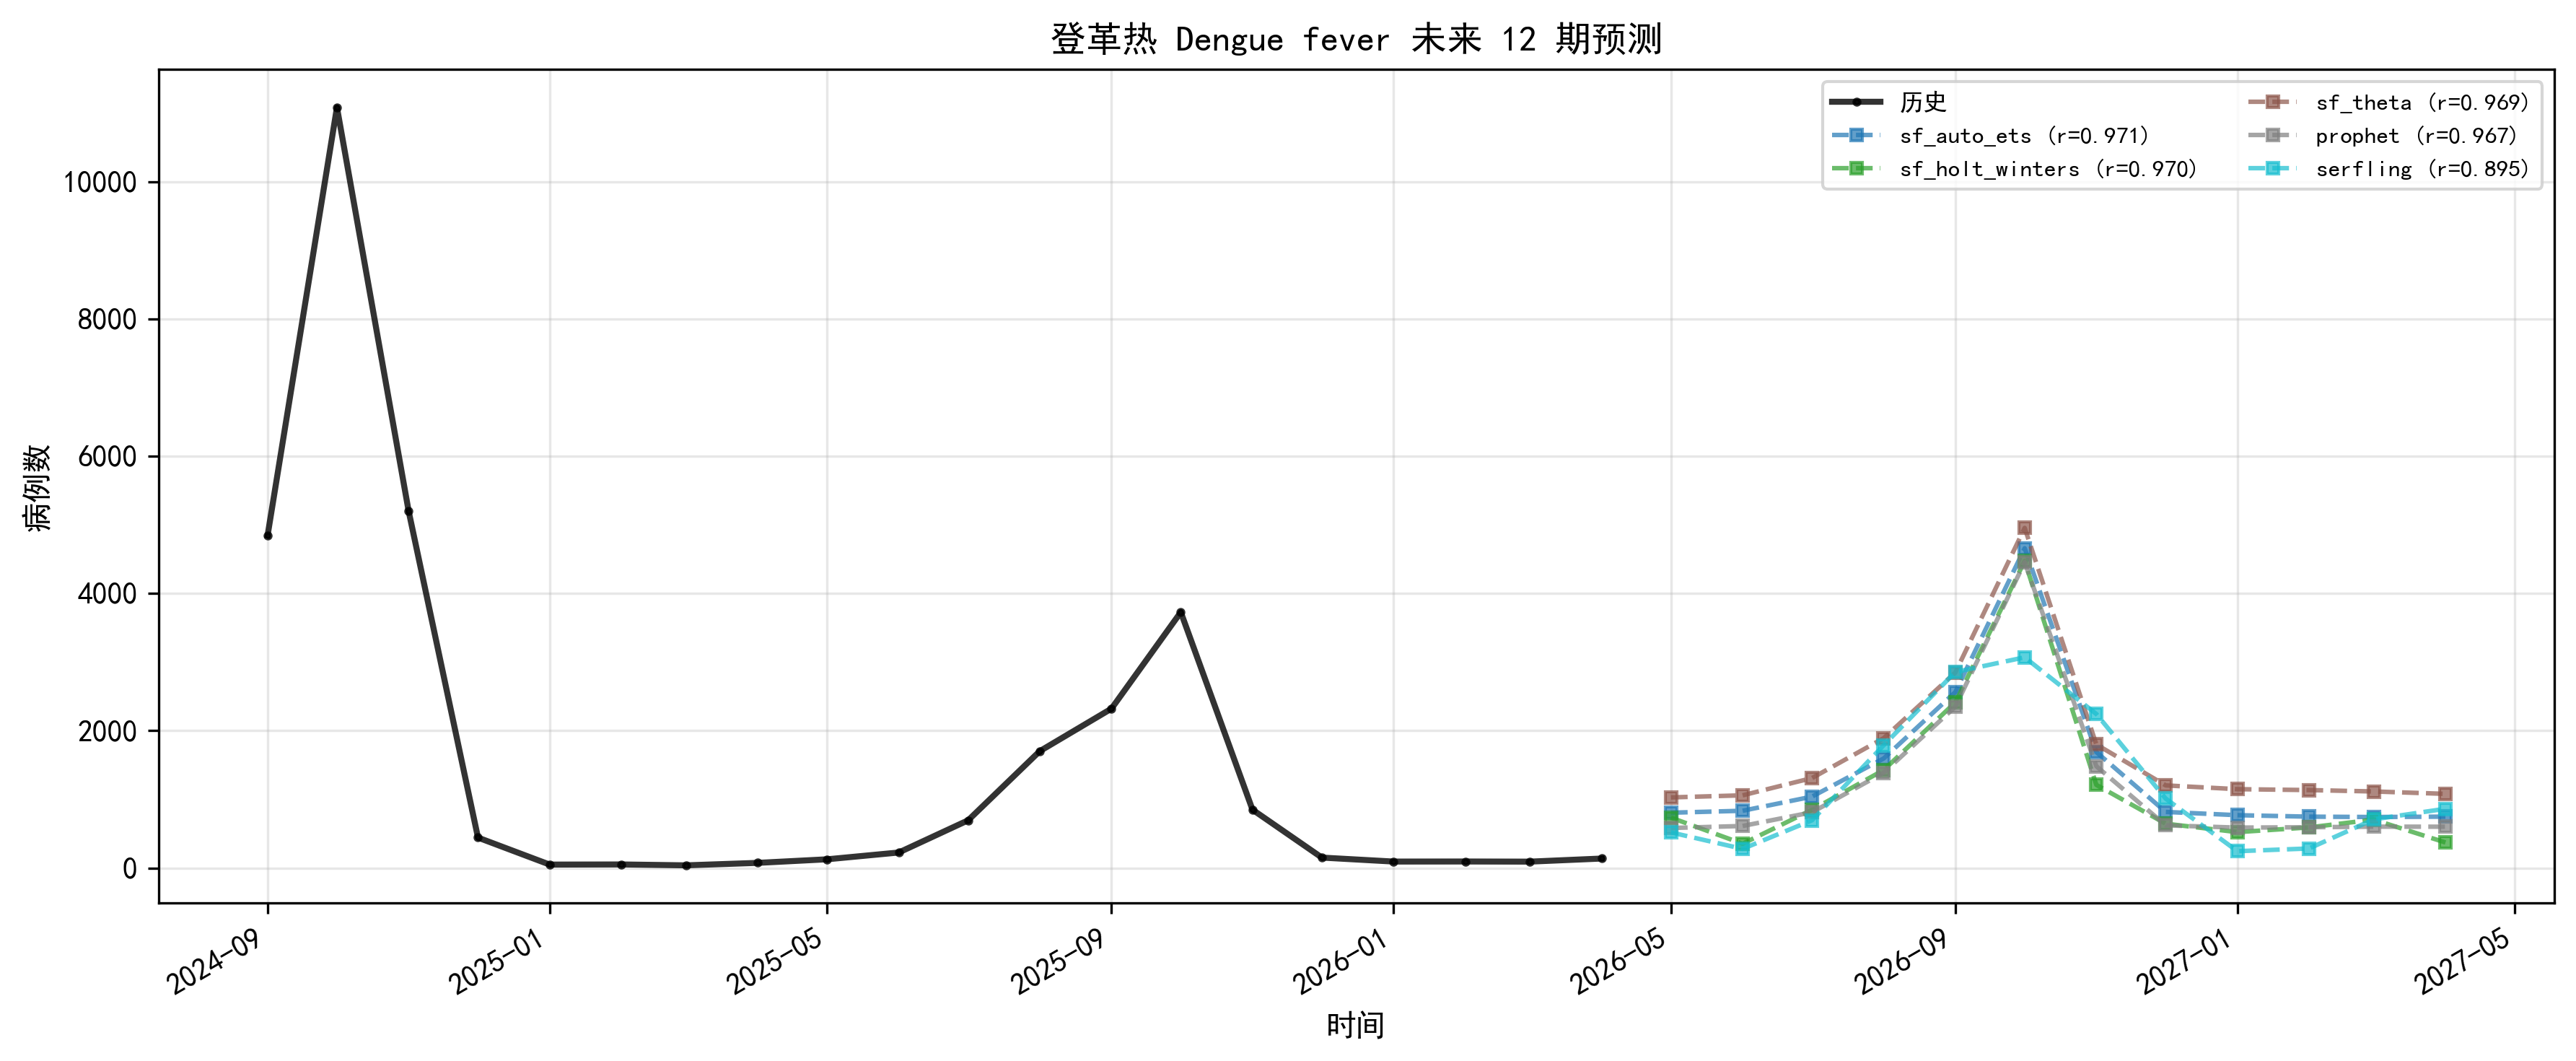

In [9]:
hist = runtime.data_table.tail(20)
pred = runtime.predict(horizon=12, level=95)

plot_forecast(
    hist_df=hist,
    pred_df=pred,
    metrics_df=vault.metrics,
    title=f"{DISEASE} 未来 12 期预测",
)

In [15]:
runtime.refit()

  refit sf_auto_ets ... OK
  refit sf_holt_winters ... OK
  refit sf_theta ... OK
  refit prophet ... FAILED: Prophet.__init__() got an unexpected keyword argument 'prophet_kwargs'
  refit serfling ... OK
  risk_quantile refit OK
  risk_zscore refit OK

全部重训完成，共 5 个模型。


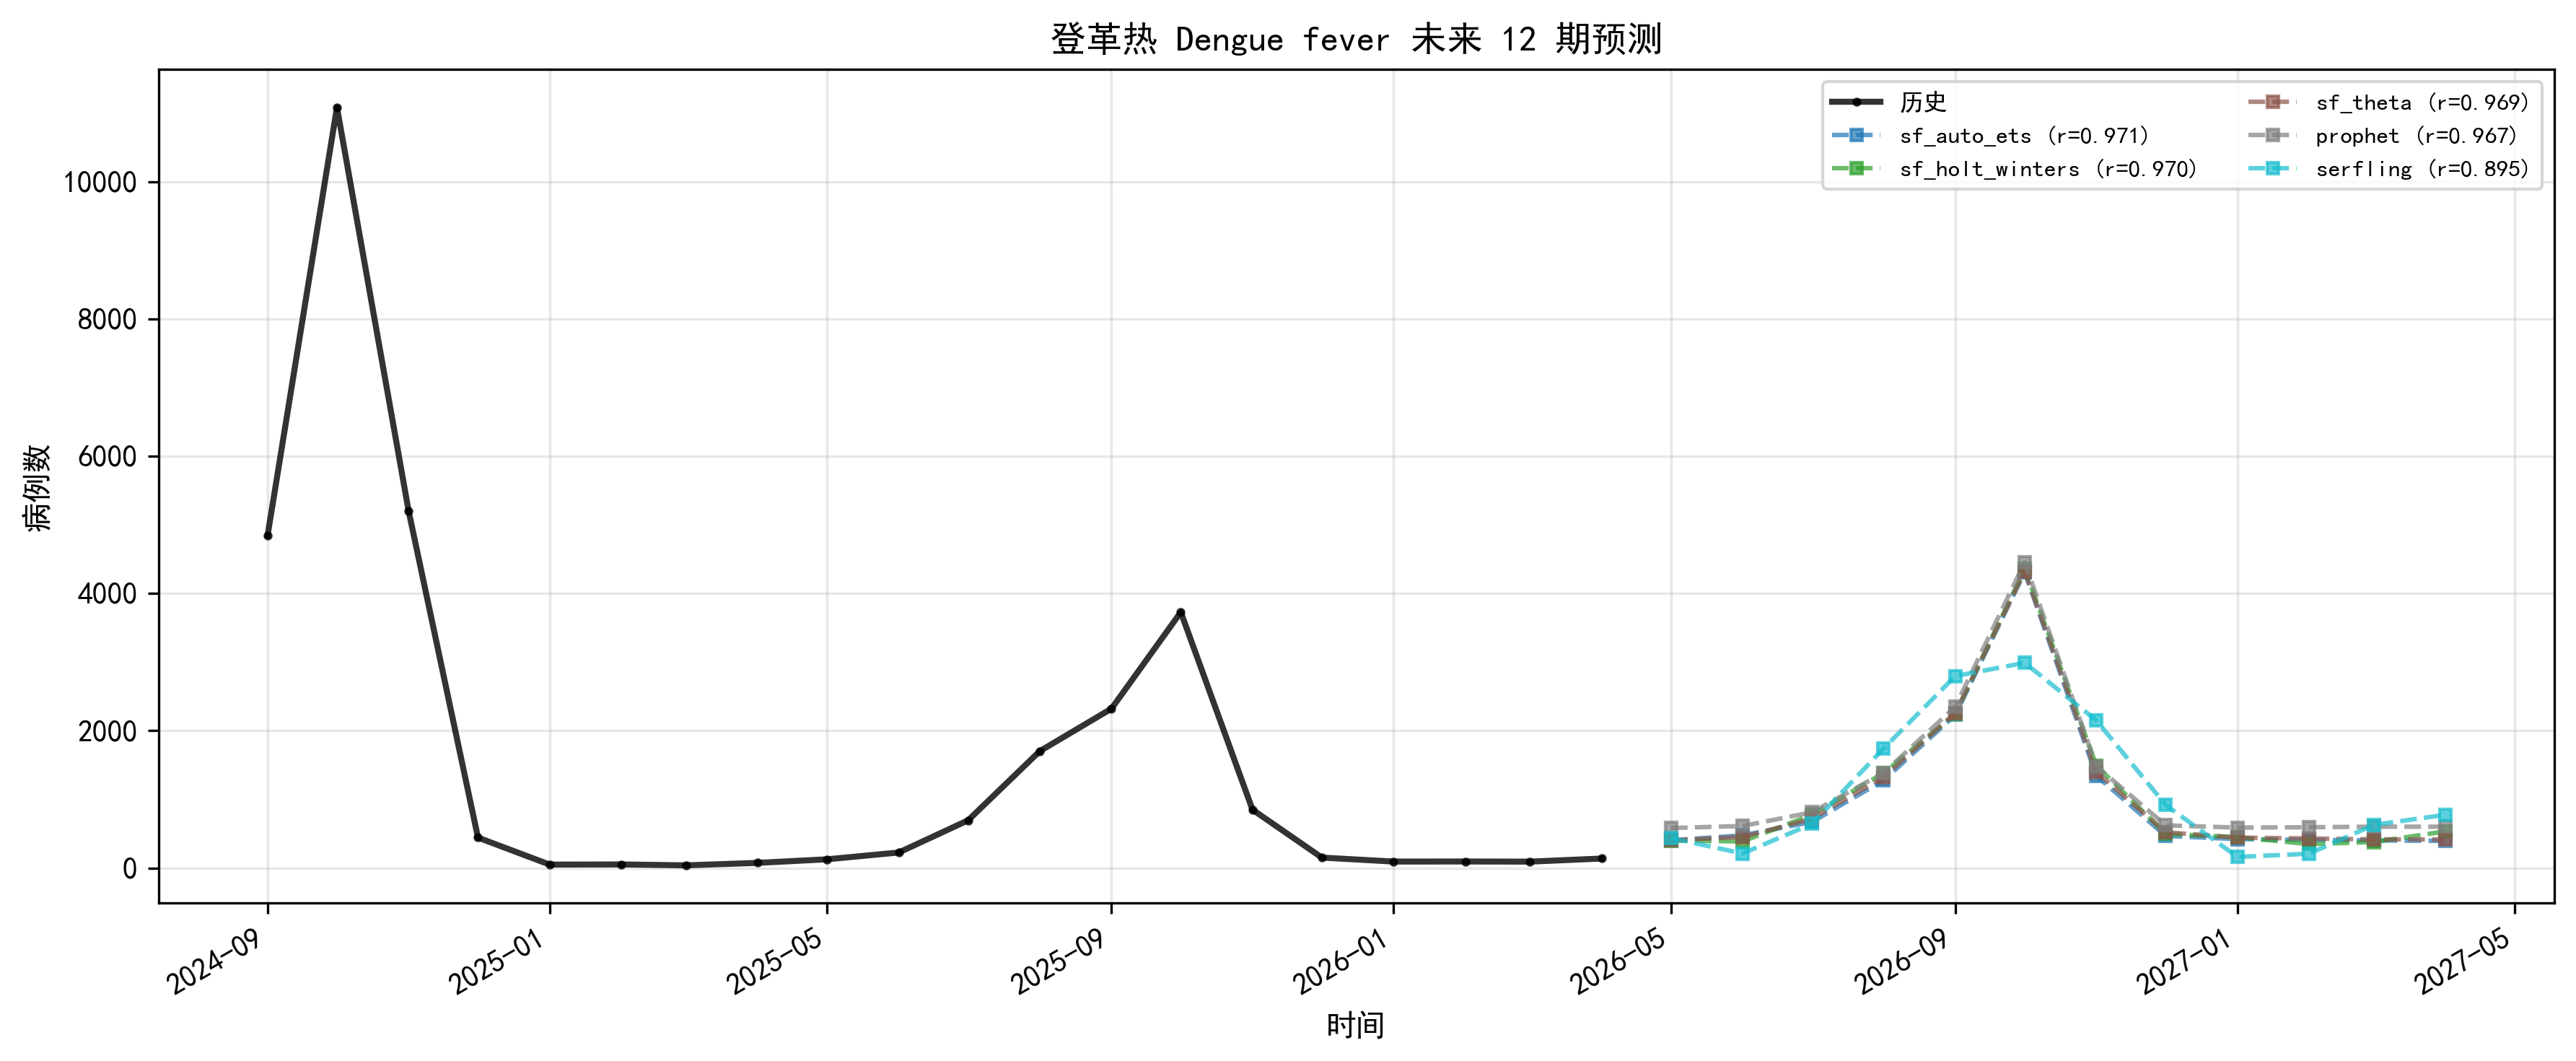

In [16]:
hist = runtime.data_table.tail(20)
pred = runtime.predict(horizon=12, level=95)

plot_forecast(
    hist_df=hist,
    pred_df=pred,
    metrics_df=vault.metrics,
    title=f"{DISEASE} 未来 12 期预测",
)

In [17]:
pred

,time,sf_auto_ets,sf_holt_winters,sf_theta,prophet,serfling,sf_auto_ets_lo,sf_auto_ets_hi,sf_holt_winters_lo,sf_holt_winters_hi,...,sf_holt_winters_quantile,prophet_quantile,serfling_quantile,sf_theta_quantile,sf_auto_ets_quantile,sf_holt_winters_zscore,prophet_zscore,serfling_zscore,sf_theta_zscore,sf_auto_ets_zscore
0,2026-05-01,400.919067,399.481964,403.262360,582.113647,436.531250,-4111.187012,4913.024902,-4117.645508,4916.609863,...,3,3,3,3,3,3,3,3,3,3
1,2026-06-01,475.340332,386.384979,450.948242,611.442627,210.060837,-4039.554688,4990.235352,-4130.747559,4903.517578,...,3,3,2,3,3,1,2,0,1,2
2,2026-07-01,670.437805,774.927551,716.158081,810.827942,642.785950,-3847.244629,5188.120117,-3742.210693,5292.065918,...,1,1,1,1,1,0,1,0,0,0
3,2026-08-01,1277.457886,1382.616943,1323.828613,1387.303711,1741.120850,-3243.010010,5797.925781,-3134.527588,5899.761230,...,1,1,1,1,1,0,0,0,0,0
4,2026-09-01,2230.088135,2247.890137,2259.064453,2349.130371,2796.154053,-2293.163818,6753.339844,-2269.261719,6765.041504,...,1,1,1,1,1,0,0,0,0,0
5,2026-10-01,4311.177734,4355.544922,4322.005859,4453.884277,2989.345215,-214.856155,8837.211914,-161.614502,8872.705078,...,1,1,1,1,1,0,0,0,0,0
6,2026-11-01,1342.709351,1491.722656,1394.633179,1482.129150,2148.828125,-3186.105225,5871.523926,-3025.445801,6008.891113,...,1,1,1,1,1,0,0,0,0,0
7,2026-12-01,466.575378,497.415894,520.221802,620.972046,916.694275,-4065.018066,4998.168945,-4019.762207,5014.594238,...,3,3,3,3,3,3,3,3,3,3
8,2027-01-01,420.424744,448.278809,442.040985,587.655701,161.200027,-4113.945801,4954.795410,-4068.910156,4965.467773,...,3,3,3,3,3,3,3,3,3,3
9,2027-02-01,408.808258,347.756897,429.704651,593.231323,207.142044,-4128.337891,4945.954102,-4169.443848,4864.957520,...,3,3,3,3,3,3,3,3,3,3
